# Malicious URL Detection Using Machine Learning
## Udita Pericharla DSC 235 601 (Fall 2024)
### December 5th, 2024. 

## 1.) Problem and Purpose
### In recent years, the increased use of the internet also means there has been an increase in cybersecurity threats, especially phishing attacks. Cisco's 2021 Cybersecurity Threat Trends report claimed that in 2021 alone, phishing attacks surged compared to 2020, with 86% of organizations reporting that at least one employee clicked on a phishing link, leading to potential data breaches. Phishing contributes to approximately 90% of all data breaches, especially during crucial times like the holiday shopping season in November and December when users are most vulnerable.

### Since I’ve seen the real-life impact of phishing risks, for example when my mom fell a suspicious link that led to a virus, this personal experience makes the issue relatable and motivated me to find a solution.

### I wanted to explore a solution that helps prevent such scenarios by analyzing URLs and predicting their safety.

### The goal of this project is to create a machine learning model that can classify URLs as either malicious or safe using a dataset of URLs and their features

## 2.) Datset

### My dataset comes from the UCSD Malicious URL Dataset. This existing dataset contains labeled data for both safe and malicious URLs.  This dataset contains 651,191 rows and 2 columns: url (the web address being analyzed) and type (the label indicating whether the URL is benign, phishing, or defacement). The dataset includes thousands of samples, making it a great resource for machine learning.





In [14]:
# Dataset 
import pandas as pd

df = pd.read_csv('malicious_phish.csv')

print("Dataset Info:")
print(df.info())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nLabel Distribution:")
print(df['type'].value_counts())

df = df.drop_duplicates()
print(f"\nDataset after removing duplicates: {df.shape}")

Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 651191 entries, 0 to 651190
Data columns (total 2 columns):
 #   Column  Non-Null Count   Dtype 
---  ------  --------------   ----- 
 0   url     651191 non-null  object
 1   type    651191 non-null  object
dtypes: object(2)
memory usage: 9.9+ MB
None

Missing Values:
url     0
type    0
dtype: int64

Label Distribution:
type
benign        428103
defacement     96457
phishing       94111
malware        32520
Name: count, dtype: int64

Dataset after removing duplicates: (641125, 2)


### One of the first steps in my analysis was understanding the structure of the data and determining which features were most relevant for predicting a URL's safety. I wnated to explore this dataset even more and break it down further to get a more in depth, but clear understanding of it's elements. Instead of using traditional text preprocessing techniques like tokenization or vectorization, I manually extracted numerical features from the URL strings. After doing some feature engineering/processing/removing all duplicate entries, the new dataset I made came down to 641,125 rows and 14 columns. Some special features include URL length, counts of special characters like @, ?, %, and /, and binary flags for the presence of suspicious keywords like 'login', 'verify', 'secure', and 'free'. These features converted the textual data into numerical form for easy read and ready for use in the machine learning models. Each column are aspects that are commonly found in malicious URLs, therefore detecting them is key to being able to analyze and avoid these harmful links. This in depth dataset provided the foundation for training, evaluating my machine learning model, and overall shows a clearly understanding of what components each URl has!

In [16]:
# Feature Engineering 
df['url_length'] = df['url'].apply(len)

special_chars = ['@', '?', '%', '.', '=', '-', '/']
for char in special_chars:
    df[f'count_{char}'] = df['url'].apply(lambda x: x.count(char))

keywords = ['secure', 'login', 'free', 'verify']
for keyword in keywords:
    df[f'has_{keyword}'] = df['url'].apply(lambda x: int(keyword in x.lower()))

print("\nUpdated Dataset Sample:")
print(df.head())

df.to_csv('processed_malicious_phish.csv', index=False)


Updated Dataset Sample:
                                                 url        type  url_length  \
0                                   br-icloud.com.br    phishing          16   
1                mp3raid.com/music/krizz_kaliko.html      benign          35   
2                    bopsecrets.org/rexroth/cr/1.htm      benign          31   
3  http://www.garage-pirenne.be/index.php?option=...  defacement          88   
4  http://adventure-nicaragua.net/index.php?optio...  defacement         235   

   count_@  count_?  count_%  count_.  count_=  count_-  count_/  has_secure  \
0        0        0        0        2        0        1        0           0   
1        0        0        0        2        0        0        2           0   
2        0        0        0        2        0        0        3           0   
3        0        1        0        3        4        1        3           0   
4        0        1        0        2        3        1        3           0   

   has_login 

## 3.) Analysis
### Now onto training and testing the model! After preprocessing the data, I split the dataset into training and testing sets using an 80-20 split. This ensured that 80% of the data was used for training the model, while 20% was reserved for testing and evaluation. 

### After importing pandas library I used the train_test_split function from sklearn.model_selection, it basically splits the dataset into training and testing subsets. Within this function, some parameters I set were x:the feature matrix (all columns except url, type, and type_encoded) and y: the target variable (type_encoded). Next I made the test_size=0.2: which reserves 20% of the data for testing. Also used the random_state parameter to set the seed value for the random number generator (random_state=42). This ensures reproducibility by fixing the random seed. I just picked 42 because my mom is 42 years old but you may replace it with any number you would like. 

### Moving forward I chose to train a Logistic Regression model. This is because we have learned about logistic regression models in class, but also they're an effective algorithm when it comes down to doing multiple tasks efficiently. I optimized the model using 1,000 iterations and the 'lbfgs' solver, which is well-suited for large datasets. During training, I also addressed the class imbalance by assigning higher weights to the minority classes. This adjustment helped improve recall for phishing and malware URLs, ensuring the model didn’t overlook them.

Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 641125 entries, 0 to 641124
Data columns (total 14 columns):
 #   Column      Non-Null Count   Dtype 
---  ------      --------------   ----- 
 0   url         641125 non-null  object
 1   type        641125 non-null  object
 2   url_length  641125 non-null  int64 
 3   count_@     641125 non-null  int64 
 4   count_?     641125 non-null  int64 
 5   count_%     641125 non-null  int64 
 6   count_.     641125 non-null  int64 
 7   count_=     641125 non-null  int64 
 8   count_-     641125 non-null  int64 
 9   count_/     641125 non-null  int64 
 10  has_secure  641125 non-null  int64 
 11  has_login   641125 non-null  int64 
 12  has_free    641125 non-null  int64 
 13  has_verify  641125 non-null  int64 
dtypes: int64(12), object(2)
memory usage: 68.5+ MB
None

Checking for missing values in the target:
23645

Found NaN values. Dropping rows with missing target values...

After cleaning, NaN values in target column:
0



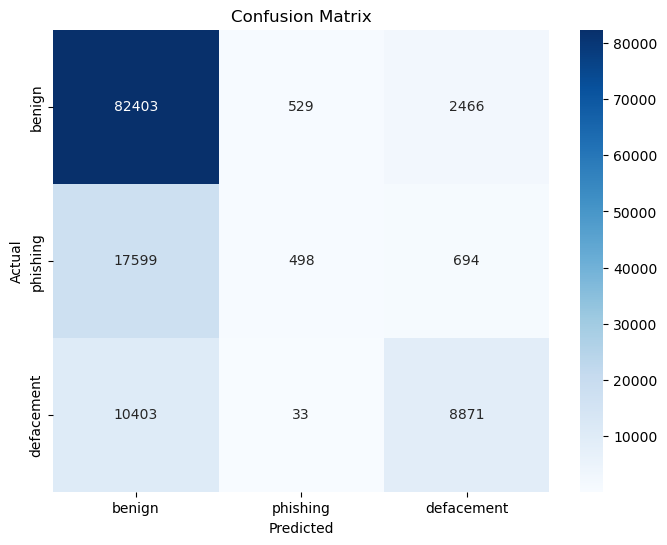

In [18]:
# Analysis Step 3
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

df = pd.read_csv('processed_malicious_phish.csv')

print("Dataset Info:")
print(df.info())

target_mapping = {'benign': 0, 'phishing': 1, 'defacement': 2}
df['type_encoded'] = df['type'].map(target_mapping)

print("\nChecking for missing values in the target:")
print(df['type_encoded'].isnull().sum())

if df['type_encoded'].isnull().sum() > 0:
    print("\nFound NaN values. Dropping rows with missing target values...")
    df = df.dropna(subset=['type_encoded'])

print("\nAfter cleaning, NaN values in target column:")
print(df['type_encoded'].isnull().sum())

X = df.drop(columns=['url', 'type', 'type_encoded'])
y = df['type_encoded']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("\nTraining Set Shape:", X_train.shape)
print("Testing Set Shape:", X_test.shape)

print("\nTraining Logistic Regression Model...")
model = LogisticRegression(max_iter=1000, multi_class='ovr', solver='lbfgs')
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
print(f"\nModel Accuracy: {accuracy:.2f}\n")

print("Classification Report:")
print(classification_report(y_test, y_pred))

conf_matrix = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues',
            xticklabels=target_mapping.keys(), yticklabels=target_mapping.keys())
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

## 4.) Results 
### Once the model was trained, I evaluated its performance using the test set. Here’s a summary of the results: 
### Accuracy: The model achieved an accuracy of 74%.
### The F1-score for benign URLs was 0.84, which is strong.
### Although, for phishing URLs, the F1-score was lower (0.05), indicating the challenge of detecting minority classes.

## 5.) Visulaization
### Above you can see I used a Confusion Matrix. The matrix showed that the model correctly classified most benign URLs but struggled to distinguish phishing and defacement URLs. I visualized the performance using a classification report heatmap too. These tools helped identify clearly where the model performed well and where it needed improvement.

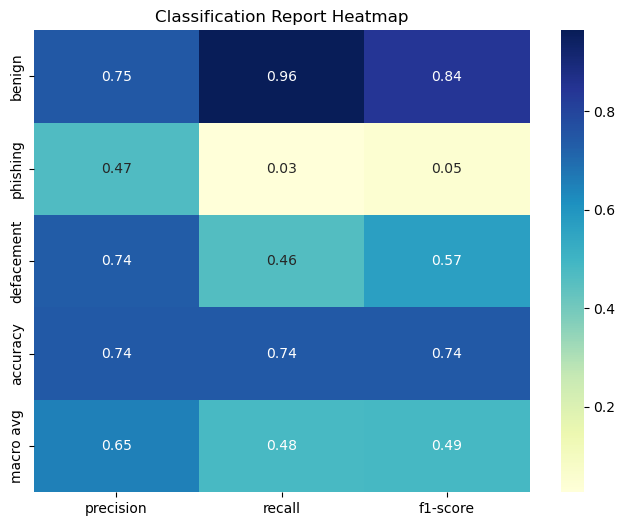

In [20]:
from sklearn.metrics import classification_report
import pandas as pd

# Generate classification report
report = classification_report(y_test, y_pred, target_names=target_mapping.keys(), output_dict=True)

report_df = pd.DataFrame(report).transpose()

plt.figure(figsize=(8, 6))
sns.heatmap(report_df.iloc[:-1, :-1], annot=True, cmap="YlGnBu", fmt='.2f')
plt.title("Classification Report Heatmap")
plt.show()

## 6.) Summary
### In summary, this project demonstrates how machine learning can be applied to detect malicious URLs, addressing a real-world problem in cybersecurity. By preprocessing the data, engineering features, and training a logistic regression model, I built a foundation for URL detection/classification.

## 7.) Insights
### While the model performed well for benign URLs, improving its ability to detect phishing and malware remains a key challenge.
### Three insights I gained were that it showed keyword relevance, certain keywords in might b present in malicious URLs compared to safe ones, such as "login," "free," or "verify,". Another insight I gained was that malicious URLs often use URL shorteners to disguise their true destination, making URL length and structure a critical feature for detection accuracy. Lastly, I learned that A high recall score shows that the model is good at catching most malicious URLs, even if some safe URLs are misclassified. 

### Most aspects of my project went the way I wanted. It was rough in the beginning because I chose a difficuly dataset to work with and it was hard to get it to load onto my notebook. Therefore picking an easier dataset to work with and load was helpful in making the project fow. The model performed well with benign URLs, as expected, highlighting that it effectively distinguishes safe URLs from malicious ones. For the benign URLs especially, it had a strong performance. The model shows high recall (0.96) and F1-score (0.84) for benign URLs, meaning it is very good at identifying safe URLs without missing many (very proud!). I would say one challenge as seen would be the extremely low recall for phishing URLs was unexpected and shows a major limitation in the model’s ability to detect high-risk cases.